# Hwang et al. 2022 — PDAC
## 04 · Expression — EMT-transcription-factor axis on the manifold

*(Renumbered from 06: with **Gate 2 = NO-GO / Gate 3 = NA** the embryonic developmental pattern is
absent, so the branching-only correlation (04) and modules (05) notebooks are **not** produced. This
unconditional EMT-TF expression step is always the final notebook, following signatures directly —
§6 renumbering.)*

Per the derive-don't-inherit mandate, a candidate EMT-TF panel — canonical Snail/Zeb/Twist **plus
the mesenchymal FOXC and PRRX families** (VIM excluded — it is a mesenchymal marker, not a
transcription factor; 04_test / Chen) — is scored on *this* manifold, gated on detectable
expression (>3%), and the data choose the two most spatially-separated factors. Because the manifold
is **non-trajectory** here (Gate 2 NO-GO), this is a descriptive readout of where EMT-TFs sit on the
malignant manifold, not an ordering along a validated developmental axis. Deliverable:
`expression.pdf`.

In [ ]:
import os, sys, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the processed manifold
Per the §6 table the expression step reads the processed data. `signatures.h5ad` is that same
manifold with pseudotime `t` and the deliverable UMAP orientation already attached, so the panel
shares one orientation with 01–03.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 63997 | pseudotime range 0.0 -> 11.36


### Derive the two most end-specific EMT-TFs (data-driven, detection-gated)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root-side) vs
late pseudotime tercile, and Spearman correlation with pseudotime. Factors below a 3% expression
floor are too sparse to overlay. Among the expressed factors, the most-negative and most-positive
rho mark the two ends of the manifold's principal axis.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.iloc[0]['TF']; late_tf = ok.iloc[-1]['TF']
print(f'\nexpressed (>3%) factors: {list(ok.TF)}')
print(f'derived pair: {early_tf} (root-side) <-> {late_tf} (far end)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
  ZEB2      0.020       0.041      0.022    -0.011
 PRRX1      0.021       0.027      0.020     0.002
TWIST1      0.001       0.002      0.002     0.012
 SNAI1      0.001       0.000      0.001     0.016
TWIST2      0.001       0.001      0.002     0.018
 FOXC2      0.004       0.003      0.006     0.027
 FOXC1      0.036       0.028      0.055     0.085
 PRRX2      0.042       0.026      0.059     0.086
 SNAI2      0.021       0.016      0.041     0.088
  ZEB1      0.157       0.137      0.274     0.149

expressed (>3%) factors: ['FOXC1', 'PRRX2', 'ZEB1']
derived pair: FOXC1 (root-side) <-> ZEB1 (far end)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, **categorical thresholded-expresser overlay on a grey manifold**
(not a continuous single-gene colormap; 04_test / Sun). Each factor is thresholded at the upper
quartile of its expressing cells; the more widely-expressed factor is drawn first, the sparser one
on top. Blue = root-side factor, red = far-end factor. Consistent inverted orientation.

FOXC1: 3.6% expressing; 583 shown (upper quartile), mean pseudotime of shown = 0.46 (all = 0.48)
ZEB1: 15.7% expressing; 2510 shown (upper quartile), mean pseudotime of shown = 0.49 (all = 0.48)
saved expression.pdf


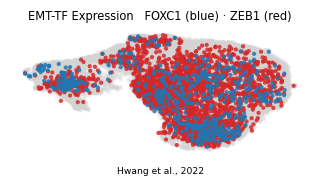

In [ ]:
xy = adata.obsm['X_umap']
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
# consistent inverted orientation (same as 01-03); apply last so it is not undone by a later lim call
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title(f'EMT-TF Expression   {early_tf} (blue) · {late_tf} (red)', size=7.5)
ax.text(.5,-.14,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight', dpi=200)
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')